# KUKA Feature Selection Experiments for AE Anomaly Detection

Implemented feature-selection experiments:

1. all features;
2. near-constant feature removal;
3. near-constant + correlation-based redundancy pruning;
4. top-$m$ KS-statistic features;
5. top-$m$ AE reconstruction-separation features.

The split is produced by `dataset.kuka_splits.split_kuka_numpy`, the same splitting function used by the current `train_ae.py` and `train_aae.py`. Preprocessing is fitted only on training data. Supervised feature rankings use validation labels only. Test data are used only for final evaluation.

In [2]:
from pathlib import Path
import sys
import os
import random
import json

import numpy as np
import pandas as pd

import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    precision_recall_curve,
    auc,
    confusion_matrix,
    classification_report,
)

# This notebook is intended to be placed in the project root, next to train_ae.py.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "dataset").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from dataset.kuka_splits import split_kuka_numpy
from dataset.kuka_dataset import KukaDataset
from processing.kuka_processing import KukaPreprocessor
from models.AE import AE
from utils import compute_threshold

## 1. Configuration

Set `EPOCHS` low while debugging. For final experiments, use the same number of epochs used for your AE baseline.

In [3]:
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

SEED = 123
BATCH_SIZE = 1024
LATENT_DIM = 4
LR = 1e-3
EPOCHS = 50          # increase for final runs, e.g. 300 or 1500
QUANTILE = 0.85
TOP_K = 5
F_BETA = 2.0

CONSTANT_EPS = 1e-8
CORR_THRESHOLD = 0.98
M_VALUES = [10, 20, 40, 60]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

device(type='cuda')

In [4]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

## 2. Load dataset split

In [6]:
splits = split_kuka_numpy(DATA_DIR, seed=SEED, binary_labels=True)

print("x_train:", splits.x_train.shape, "y_train:", splits.y_train.shape, np.unique(splits.y_train, return_counts=True))
print("x_val:  ", splits.x_val.shape,   "y_val:  ", splits.y_val.shape,   np.unique(splits.y_val, return_counts=True))
print("x_test: ", splits.x_test.shape,  "y_test: ", splits.y_test.shape,  np.unique(splits.y_test, return_counts=True))

n_features_raw = splits.x_train.shape[1]
print("Raw feature count:", n_features_raw)

x_train: (163654, 86) y_train: (163654,) (array([0], dtype=int64), array([163654], dtype=int64))
x_val:   (55837, 86) y_val:   (55837,) (array([0, 1], dtype=int64), array([35068, 20769], dtype=int64))
x_test:  (55839, 86) y_test:  (55839,) (array([0, 1], dtype=int64), array([35070, 20769], dtype=int64))
Raw feature count: 86


## 3. Load feature names robustly

`KukaNormal.npy` has no label column. `KukaSlow.npy` has the label as the last column. Therefore, the expected number of feature names is `splits.x_train.shape[1]`. If `KukaColumnNames.npy` contains one extra label name, the last name is dropped automatically.

In [7]:
def load_feature_names(data_dir: Path, n_features: int) -> np.ndarray:
    path = data_dir / "KukaColumnNames.npy"

    if not path.exists():
        print("KukaColumnNames.npy not found. Using generic feature names.")
        return np.array([f"feature_{i}" for i in range(n_features)], dtype=object)

    names = np.load(path, allow_pickle=True).astype(str)

    if len(names) == n_features:
        return names

    if len(names) == n_features + 1:
        print("Feature-name file has one extra column. Assuming last entry is label and dropping it.")
        return names[:-1]

    print(f"Unexpected number of feature names: {len(names)} for {n_features} features. Using generic feature names.")
    return np.array([f"feature_{i}" for i in range(n_features)], dtype=object)

feature_names = load_feature_names(DATA_DIR, n_features_raw)
assert len(feature_names) == n_features_raw

pd.DataFrame({"feature_index": np.arange(n_features_raw), "feature_name": feature_names}).head(10)

Feature-name file has one extra column. Assuming last entry is label and dropping it.


,feature_index,feature_name
0,0,action
1,1,machine_nameKuka Robot_apparent_power
2,2,machine_nameKuka Robot_current
3,3,machine_nameKuka Robot_frequency
4,4,machine_nameKuka Robot_phase_angle
5,5,machine_nameKuka Robot_power
6,6,machine_nameKuka Robot_power_factor
7,7,machine_nameKuka Robot_reactive_power
8,8,machine_nameKuka Robot_voltage
9,9,sensor_id1_AccX


## 4. Utility functions

These functions keep the notebook self-contained while reusing the project objects: `KukaPreprocessor`, `KukaDataset`, `AE`, and `compute_threshold`.

In [8]:
def make_dataloaders_for_features(selected_features, batch_size=BATCH_SIZE, normalization=True):
    """Build DataLoaders for a selected subset of original feature indices."""
    selected_features = np.asarray(selected_features, dtype=int)

    x_train_raw = splits.x_train[:, selected_features]
    x_val_raw = splits.x_val[:, selected_features]
    x_test_raw = splits.x_test[:, selected_features]

    preprocessor = KukaPreprocessor(
        normalization=normalization,
        remove_constant=False,
        corr_threshold=None,
        clip_percentiles=None,
    )

    x_train = preprocessor.fit_transform(x_train_raw)
    x_val = preprocessor.transform(x_val_raw)
    x_test = preprocessor.transform(x_test_raw)

    train_dataset = KukaDataset(x_train, splits.y_train)
    val_dataset = KukaDataset(x_val, splits.y_val)
    test_dataset = KukaDataset(x_test, splits.y_test)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, preprocessor


def ae_error_fn(pred, x, top_k=TOP_K):
    k = min(int(top_k), x.shape[1])
    return (pred - x).pow(2).topk(k, dim=1).values.mean(dim=1)


def train_ae_model(model, train_loader, device=DEVICE, lr=LR, epochs=EPOCHS):
    loss_fn = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    model.to(device)

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            recon = model(x)
            loss = loss_fn(recon, x)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        history.append(epoch_loss)

        if epoch == 0 or (epoch + 1) % max(1, epochs // 5) == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch + 1:4d}/{epochs}: loss={epoch_loss:.6f}")

    return history


def evaluate_ae_model(model, loader, threshold, top_k=TOP_K, device=DEVICE):
    all_preds, all_labels, all_errors = [], [], []

    model.eval()
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            recon = model(x)
            err = ae_error_fn(recon, x, top_k=top_k)
            preds = (err > threshold).int()

            all_preds.append(preds.cpu())
            all_labels.append(y.cpu())
            all_errors.append(err.cpu())

    return torch.cat(all_preds), torch.cat(all_labels), torch.cat(all_errors)


def compute_pointwise_metrics(labels, preds, scores, beta=F_BETA):
    y = labels.detach().cpu().numpy().astype(int).reshape(-1)
    p = preds.detach().cpu().numpy().astype(int).reshape(-1)
    s = scores.detach().cpu().numpy().astype(float).reshape(-1)

    precision_curve, recall_curve, _ = precision_recall_curve(y, s, pos_label=1)

    return {
        "precision": precision_score(y, p, zero_division=0),
        "recall": recall_score(y, p, zero_division=0),
        "f1": f1_score(y, p, zero_division=0),
        f"f_{beta:g}": fbeta_score(y, p, beta=beta, zero_division=0),
        "accuracy": accuracy_score(y, p),
        "balanced_accuracy": balanced_accuracy_score(y, p),
        "pr_auc": auc(recall_curve, precision_curve),
        "average_precision": average_precision_score(y, s),
        "n_samples": int(len(y)),
        "n_anomaly": int((y == 1).sum()),
        "n_normal": int((y == 0).sum()),
    }


def run_ae_experiment(experiment_name, selected_features, epochs=EPOCHS, seed=SEED):
    """Train and evaluate an AE on a specific feature subset."""
    selected_features = np.asarray(selected_features, dtype=int)

    if len(selected_features) == 0:
        raise ValueError(f"{experiment_name}: selected feature subset is empty")

    print("=" * 80)
    print(f"Experiment: {experiment_name}")
    print(f"Selected features: {len(selected_features)}")

    set_seed(seed)

    train_loader, val_loader, test_loader, preprocessor = make_dataloaders_for_features(selected_features)

    input_dim = len(selected_features)
    model = AE(input_dim, LATENT_DIM).to(DEVICE)

    history = train_ae_model(model, train_loader, epochs=epochs)

    threshold = compute_threshold(
        model,
        val_loader,
        quantile=QUANTILE,
        err_fn=lambda pred, x: ae_error_fn(pred, x, top_k=TOP_K),
    )

    preds, labels, errors = evaluate_ae_model(model, test_loader, threshold=threshold, top_k=TOP_K)
    metrics = compute_pointwise_metrics(labels, preds, errors, beta=F_BETA)

    cm = confusion_matrix(labels.numpy(), preds.numpy(), labels=[0, 1])

    row = {
        "experiment": experiment_name,
        "n_features": int(len(selected_features)),
        "threshold": float(threshold),
        "final_train_loss": float(history[-1]),
        **metrics,
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1]),
    }

    print("Threshold:", threshold)
    print(pd.Series(row))

    return {
        "row": row,
        "model": model,
        "history": history,
        "selected_features": selected_features,
        "preprocessor": preprocessor,
        "preds": preds,
        "labels": labels,
        "errors": errors,
    }

## 5. Feature-selection methods

The methods below return indices relative to the original feature matrix.

In [10]:
def select_all_features(n_features: int) -> np.ndarray:
    return np.arange(n_features, dtype=int)


def select_nonconstant_features(x_train, eps=CONSTANT_EPS) -> np.ndarray:
    std = np.std(x_train, axis=0)
    return np.flatnonzero(std > eps)


def correlation_prune_features(x_train, candidate_features, threshold=CORR_THRESHOLD) -> np.ndarray:
    """Greedy correlation pruning in the order given by candidate_features."""
    candidate_features = np.asarray(candidate_features, dtype=int)
    x = x_train[:, candidate_features]

    if x.shape[1] <= 1:
        return candidate_features

    corr = np.corrcoef(x, rowvar=False)
    corr = np.nan_to_num(np.abs(corr), nan=0.0, posinf=0.0, neginf=0.0)

    keep_local = []
    for j in range(x.shape[1]):
        if not keep_local:
            keep_local.append(j)
            continue

        max_corr = np.max(corr[j, keep_local])
        if max_corr <= threshold:
            keep_local.append(j)

    return candidate_features[np.array(keep_local, dtype=int)]


def ks_statistic_1d(a, b):
    """Two-sample KS statistic D. Does not require scipy."""
    a = np.sort(np.asarray(a, dtype=float))
    b = np.sort(np.asarray(b, dtype=float))

    if len(a) == 0 or len(b) == 0:
        return np.nan

    values = np.concatenate([a, b])
    cdf_a = np.searchsorted(a, values, side="right") / len(a)
    cdf_b = np.searchsorted(b, values, side="right") / len(b)
    return float(np.max(np.abs(cdf_a - cdf_b)))


def rank_features_by_ks(x_val, y_val, candidate_features):
    candidate_features = np.asarray(candidate_features, dtype=int)
    y_val = np.asarray(y_val).astype(int)

    normal_mask = y_val == 0
    anomaly_mask = y_val == 1

    if normal_mask.sum() == 0 or anomaly_mask.sum() == 0:
        raise ValueError("Validation split must contain both normal and anomaly samples for KS ranking.")

    scores = []
    for f in candidate_features:
        scores.append(ks_statistic_1d(x_val[normal_mask, f], x_val[anomaly_mask, f]))

    scores = np.asarray(scores)
    order = np.argsort(scores)[::-1]

    return candidate_features[order], scores[order]


def rank_features_by_ae_reconstruction_separation(model, val_loader, candidate_features, eps=1e-8):
    """
    Rank selected input features by validation reconstruction-error separation:

        r_j = (mean_anomaly_error_j - mean_normal_error_j) / (std_normal_error_j + eps)

    candidate_features maps local model columns back to original feature indices.
    """
    model.eval()

    normal_errors = []
    anomaly_errors = []

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(DEVICE)
            recon = model(x)
            feature_err = (recon - x).pow(2).cpu()

            y = y.cpu()
            if (y == 0).any():
                normal_errors.append(feature_err[y == 0])
            if (y == 1).any():
                anomaly_errors.append(feature_err[y == 1])

    if not normal_errors or not anomaly_errors:
        raise ValueError("Validation split must contain both normal and anomaly samples.")

    normal_errors = torch.cat(normal_errors, dim=0)
    anomaly_errors = torch.cat(anomaly_errors, dim=0)

    normal_mean = normal_errors.mean(dim=0)
    normal_std = normal_errors.std(dim=0)
    anomaly_mean = anomaly_errors.mean(dim=0)

    separation = ((anomaly_mean - normal_mean) / (normal_std + eps)).numpy()
    order = np.argsort(separation)[::-1]

    candidate_features = np.asarray(candidate_features, dtype=int)
    return candidate_features[order], separation[order]

## 6. Build feature subsets

In [11]:
all_features = select_all_features(n_features_raw)
nonconstant_features = select_nonconstant_features(splits.x_train, eps=CONSTANT_EPS)
nonconstant_corr_features = correlation_prune_features(
    splits.x_train,
    nonconstant_features,
    threshold=CORR_THRESHOLD,
)

print("All features:                 ", len(all_features))
print("After near-constant removal:  ", len(nonconstant_features))
print("After correlation pruning:    ", len(nonconstant_corr_features))

removed_constant = np.setdiff1d(all_features, nonconstant_features)
removed_corr = np.setdiff1d(nonconstant_features, nonconstant_corr_features)

print("Near-constant removed:")
display(pd.DataFrame({"feature_index": removed_constant, "feature_name": feature_names[removed_constant]}))

print("Correlation-pruned removed, first 20:")
display(pd.DataFrame({"feature_index": removed_corr[:20], "feature_name": feature_names[removed_corr[:20]]}))

All features:                  86
After near-constant removal:   82
After correlation pruning:     79
Near-constant removed:


,feature_index,feature_name
0,30,sensor_id2_temp
1,63,sensor_id5_temp
2,74,sensor_id6_temp
3,85,sensor_id7_temp


Correlation-pruned removed, first 20:


,feature_index,feature_name
0,5,machine_nameKuka Robot_power
1,6,machine_nameKuka Robot_power_factor
2,80,sensor_id7_GyroZ


In [12]:
# KS ranking uses validation labels only.
# Use nonconstant features as candidates to avoid selecting degenerate channels.

ks_ranked_features, ks_scores = rank_features_by_ks(
    splits.x_val,
    splits.y_val,
    candidate_features=nonconstant_features,
)

ks_table = pd.DataFrame({
    "rank": np.arange(1, len(ks_ranked_features) + 1),
    "feature_index": ks_ranked_features,
    "feature_name": feature_names[ks_ranked_features],
    "ks_score": ks_scores,
})

ks_table.head(20)

,rank,feature_index,feature_name,ks_score
0,1,37,sensor_id3_q1,0.444422
1,2,17,sensor_id1_q3,0.413103
2,3,15,sensor_id1_q1,0.411799
3,4,72,sensor_id6_q3,0.395636
4,5,71,sensor_id6_q2,0.359868
5,6,38,sensor_id3_q2,0.357046
6,7,8,machine_nameKuka Robot_voltage,0.335216
7,8,50,sensor_id4_q3,0.333629
8,9,4,machine_nameKuka Robot_phase_angle,0.308354
9,10,6,machine_nameKuka Robot_power_factor,0.308327


## 7. Run AE experiments up to KS-based feature selection

This section trains a new AE for each feature subset. It may take time depending on `EPOCHS`.

In [13]:
experiment_outputs = []
selected_feature_tables = {}

out_all = run_ae_experiment("all_features", all_features, epochs=EPOCHS, seed=SEED)
experiment_outputs.append(out_all)
selected_feature_tables["all_features"] = all_features

out_nc = run_ae_experiment("nonconstant", nonconstant_features, epochs=EPOCHS, seed=SEED)
experiment_outputs.append(out_nc)
selected_feature_tables["nonconstant"] = nonconstant_features

out_nc_corr = run_ae_experiment("nonconstant_corr", nonconstant_corr_features, epochs=EPOCHS, seed=SEED)
experiment_outputs.append(out_nc_corr)
selected_feature_tables["nonconstant_corr"] = nonconstant_corr_features

for m in M_VALUES:
    m_eff = min(m, len(ks_ranked_features))
    selected = ks_ranked_features[:m_eff]
    name = f"top_{m_eff}_ks"
    out = run_ae_experiment(name, selected, epochs=EPOCHS, seed=SEED)
    experiment_outputs.append(out)
    selected_feature_tables[name] = selected

Experiment: all_features
Selected features: 86
Epoch    1/50: loss=0.062107
Epoch   10/50: loss=0.018083
Epoch   20/50: loss=0.016891
Epoch   30/50: loss=0.016533
Epoch   40/50: loss=0.015038
Epoch   50/50: loss=0.013885
Threshold: 0.16573050618171692
experiment           all_features
n_features                     86
threshold                0.165731
final_train_loss         0.013885
precision                0.663807
recall                   0.510328
f1                       0.577036
f_2                      0.535071
accuracy                 0.721736
balanced_accuracy        0.678631
pr_auc                    0.71144
average_precision        0.711445
n_samples                   55839
n_anomaly                   20769
n_normal                    35070
tn                          29702
fp                           5368
fn                          10170
tp                          10599
dtype: object
Experiment: nonconstant
Selected features: 82
Epoch    1/50: loss=0.061263
Epoch   10/50

## 8. Top-$m$ AE reconstruction-separation features

This method first trains an AE on a candidate feature space, then ranks features using validation reconstruction-error separation:

$$
r_j = \frac{\mu_{anom,j} - \mu_{normal,j}}{\sigma_{normal,j} + \epsilon}.
$$

The ranking uses validation labels, not test labels. Here the candidate feature space is `nonconstant_corr_features`.

In [15]:
base_model_for_recon_ranking = out_nc_corr["model"]
base_candidate_features = nonconstant_corr_features

_, val_loader_for_base, _, _ = make_dataloaders_for_features(base_candidate_features)

ae_ranked_features, ae_sep_scores = rank_features_by_ae_reconstruction_separation(
    base_model_for_recon_ranking,
    val_loader_for_base,
    candidate_features=base_candidate_features,
)

ae_sep_table = pd.DataFrame({
    "rank": np.arange(1, len(ae_ranked_features) + 1),
    "feature_index": ae_ranked_features,
    "feature_name": feature_names[ae_ranked_features],
    "ae_reconstruction_separation": ae_sep_scores,
})

ae_sep_table.head(20)

,rank,feature_index,feature_name,ae_reconstruction_separation
0,1,48,sensor_id4_q1,11.032240
1,2,50,sensor_id4_q3,9.219108
2,3,49,sensor_id4_q2,4.572853
3,4,51,sensor_id4_q4,4.233628
4,5,29,sensor_id2_q4,1.171037
5,6,83,sensor_id7_q3,1.112159
6,7,82,sensor_id7_q2,0.940472
7,8,22,sensor_id2_AccZ,0.937756
8,9,38,sensor_id3_q2,0.854640
9,10,21,sensor_id2_AccY,0.828975


In [16]:
for m in M_VALUES:
    m_eff = min(m, len(ae_ranked_features))
    selected = ae_ranked_features[:m_eff]
    name = f"top_{m_eff}_ae_recon_sep"
    out = run_ae_experiment(name, selected, epochs=EPOCHS, seed=SEED)
    experiment_outputs.append(out)
    selected_feature_tables[name] = selected

Experiment: top_10_ae_recon_sep
Selected features: 10
Epoch    1/50: loss=0.101133
Epoch   10/50: loss=0.005735
Epoch   20/50: loss=0.004141
Epoch   30/50: loss=0.003703
Epoch   40/50: loss=0.003362
Epoch   50/50: loss=0.003103
Threshold: 0.009774562902748585
experiment           top_10_ae_recon_sep
n_features                            10
threshold                       0.009775
final_train_loss                0.003103
precision                       0.702996
recall                          0.589773
f1                              0.641426
f_2                             0.609403
accuracy                        0.754741
balanced_accuracy               0.721106
pr_auc                          0.766241
average_precision               0.766245
n_samples                          55839
n_anomaly                          20769
n_normal                           35070
tn                                 29895
fp                                  5175
fn                                  8520
tp

## 9. Results summary

In [21]:
results_df = pd.DataFrame([out["row"] for out in experiment_outputs])

metric_cols = [
    "experiment", "n_features", "threshold", "final_train_loss",
    "precision", "recall", "f1", f"f_{F_BETA:g}",
    "accuracy", "balanced_accuracy", "pr_auc", "average_precision",
    "tn", "fp", "fn", "tp",
]

results_df = results_df[metric_cols]
results_df.sort_values("average_precision", ascending=False)

,experiment,n_features,threshold,final_train_loss,precision,recall,f1,f_2,accuracy,balanced_accuracy,pr_auc,average_precision,tn,fp,fn,tp
3,top_10_ks,10,0.009469,0.003124,0.765138,0.817083,0.790258,0.806137,0.838679,0.834276,0.891241,0.891243,29861,5209,3799,16970
4,top_20_ks,20,0.052493,0.011559,0.748242,0.758294,0.753234,0.756262,0.815201,0.803598,0.865789,0.865825,29771,5299,5020,15749
8,top_20_ae_recon_sep,20,0.045682,0.008948,0.737105,0.710771,0.723698,0.715886,0.798134,0.780321,0.837488,0.837491,29805,5265,6007,14762
6,top_60_ks,60,0.140260,0.013772,0.716950,0.647841,0.680645,0.660576,0.773886,0.748186,0.799986,0.799989,29758,5312,7314,13455
7,top_10_ae_recon_sep,10,0.009775,0.003103,0.702996,0.589773,0.641426,0.609403,0.754741,0.721106,0.766241,0.766245,29895,5175,8520,12249
9,top_40_ae_recon_sep,40,0.108537,0.013052,0.701473,0.582214,0.636304,0.602707,0.752449,0.717739,0.736932,0.736951,29924,5146,8677,12092
1,nonconstant,82,0.141999,0.010847,0.690555,0.569262,0.624070,0.589988,0.744909,0.709096,0.727521,0.727546,29772,5298,8946,11823
5,top_40_ks,40,0.142312,0.020100,0.665630,0.505128,0.574377,0.530722,0.721557,0.677428,0.727142,0.727146,29800,5270,10278,10491
10,top_60_ae_recon_sep,60,0.121219,0.011005,0.677454,0.516058,0.585843,0.541877,0.728613,0.685274,0.715531,0.715537,29967,5103,10051,10718
0,all_features,86,0.165731,0.013885,0.663807,0.510328,0.577036,0.535071,0.721736,0.678631,0.711440,0.711445,29702,5368,10170,10599


In [23]:
results_path = RESULTS_DIR / "feature_selection_results.csv"
ks_path = RESULTS_DIR / "feature_selection_ks_ranking.csv"
ae_sep_path = RESULTS_DIR / "feature_selection_ae_recon_sep_ranking.csv"
selected_path = RESULTS_DIR / "feature_selection_selected_features.csv"

results_df.to_csv(results_path, index=False)
ks_table.to_csv(ks_path, index=False)
ae_sep_table.to_csv(ae_sep_path, index=False)

selected_rows = []
for experiment, indices in selected_feature_tables.items():
    for rank, idx in enumerate(indices, start=1):
        selected_rows.append({
            "experiment": experiment,
            "rank": rank,
            "feature_index": int(idx),
            "feature_name": str(feature_names[idx]),
        })

selected_df = pd.DataFrame(selected_rows)
selected_df.to_csv(selected_path, index=False)

print("Saved results.")

Saved results.


## 10. Visual comparison

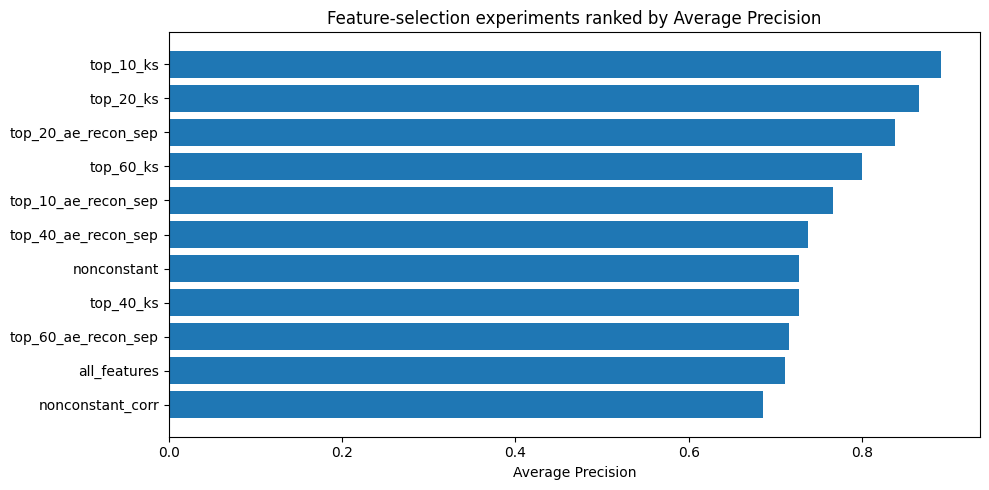

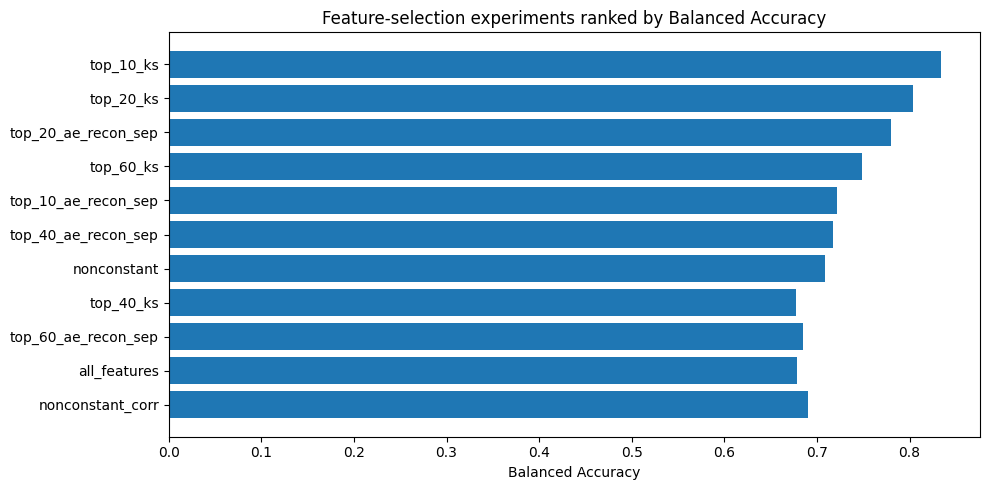

In [24]:
plot_df = results_df.sort_values("average_precision", ascending=True)

plt.figure(figsize=(10, max(5, 0.4 * len(plot_df))))
plt.barh(plot_df["experiment"], plot_df["average_precision"])
plt.xlabel("Average Precision")
plt.title("Feature-selection experiments ranked by Average Precision")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, max(5, 0.4 * len(plot_df))))
plt.barh(plot_df["experiment"], plot_df["balanced_accuracy"])
plt.xlabel("Balanced Accuracy")
plt.title("Feature-selection experiments ranked by Balanced Accuracy")
plt.tight_layout()
plt.show()

## 11. Inspect selected features

Use these tables for the report and for deciding which feature-selection protocol to carry into the AE-vs-AAE comparison.

In [27]:
EXPERIMENT_TO_INSPECT = "top_10_ks"

if EXPERIMENT_TO_INSPECT in selected_feature_tables:
    idx = selected_feature_tables[EXPERIMENT_TO_INSPECT]
    display(pd.DataFrame({
        "rank": np.arange(1, len(idx) + 1),
        "feature_index": idx,
        "feature_name": feature_names[idx],
    }))
else:
    print("Available experiments:")
    print(list(selected_feature_tables.keys()))

,rank,feature_index,feature_name
0,1,37,sensor_id3_q1
1,2,17,sensor_id1_q3
2,3,15,sensor_id1_q1
3,4,72,sensor_id6_q3
4,5,71,sensor_id6_q2
5,6,38,sensor_id3_q2
6,7,8,machine_nameKuka Robot_voltage
7,8,50,sensor_id4_q3
8,9,4,machine_nameKuka Robot_phase_angle
9,10,6,machine_nameKuka Robot_power_factor
